# A native NEXAFSFit single-spectrum fit

This example fits the same synthetic CSV and initial model as the GUI getting-started
tutorial. It calls the supplied **NEXAFSFit** numerical package directly, without
Qt or the GUI adapter. It covers model evaluation, optimisation, parameter
interpretation and full-grid residual masking.

The data are two Gaussian peaks plus a linear background and small seeded noise.
Their energies are illustrative, not assignments to experimental features.
Run from this source checkout with the **nexafs-fit** Python kernel.

For environment and kernel setup, see [Python and Jupyter basics](getting-started.md#environment-and-source).


In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the accompanying book data from a notebook or repository working folder.
search_roots = [Path.cwd(), *Path.cwd().parents]
candidates = [root / "docs" / "book" for root in search_roots] + search_roots
book_root = next((root for root in candidates
                  if (root / "myst.yml").is_file()
                  and (root / "examples" / "data" / "two-peak-spectrum.csv").is_file()), None)
if book_root is None:
    raise FileNotFoundError("Run inside the NEXAFSFit source checkout containing docs/book.")
repository = book_root.parent.parent
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))

from NEXAFSFit import (
    build_params_from_specs, model_components_from_specs,
    fit_spectrum_generic, residual_from_specs,
)
data_directory = book_root / "examples" / "data"

## Load the data and starting specifications

The CSV has one header row, energy in eV and intensity in arbitrary units. The
JSON file is also a GUI-loadable model. Here we read only its native
`edge_cfg` and `peak_specs` dictionaries: this simple example does not rely on
GUI extensions for linked peaks or multiple edges.

No I0, foil or photodiode processing is appropriate for this already prepared
synthetic dataset.

In [2]:
data = np.loadtxt(data_directory / "two-peak-spectrum.csv", delimiter=",", skiprows=1)
energy, intensity = data[:, 0], data[:, 1]
model_document = json.loads((data_directory / "two-peak-model.json").read_text())
truth_document = json.loads((data_directory / "two-peak-truth.json").read_text())
truth = truth_document["parameters"]

edge_cfg = deepcopy(model_document["edge_cfg"])
peak_specs = deepcopy(model_document["peak_specs"])
assert energy.size == 221 and np.all(np.diff(energy) > 0)
assert np.isfinite(data).all()

initial_params = build_params_from_specs(edge_cfg, peak_specs)
initial = model_components_from_specs(initial_params, energy,
                                     edge_cfg=edge_cfg, peak_specs=peak_specs)
display(pd.DataFrame([
    {"parameter": name, "start": p.value, "min": p.min, "max": p.max, "free": p.vary}
    for name, p in initial_params.items()
]))

,parameter,start,min,max,free
0,b0,0.020,-0.20,0.50,True
1,b1,0.002,-0.02,0.02,False
2,P1_A,1.200,0.00,5.00,True
3,P1_mu,284.800,284.20,285.80,True
4,P1_sigma,0.400,0.08,1.00,True
5,P2_A,0.700,0.00,5.00,True
6,P2_mu,287.500,286.40,288.20,True
7,P2_sigma,0.650,0.10,1.20,True


## Fit with the native convenience function

The native function returns an lmfit optimisation result and a component
dictionary. `A` is integrated area; `sigma` is Gaussian standard deviation.
The background level is free and its slope is fixed. No edge, gain or energy
shift is needed here.

The 10,000-evaluation budget is ample for this small example. Like the GUI budget,
it counts residual evaluations, including numerical derivative work.

In [3]:
result, components = fit_spectrum_generic(
    energy, intensity, edge_cfg, peak_specs,
    max_nfev=10_000, ftol=1e-8, xtol=1e-8, gtol=1e-8,
)
assert result.success, result.message
assert np.isfinite(components["total"]).all()
residual = intensity - components["total"]

parameter_table = pd.DataFrame([
    {"parameter": name, "fitted": p.value, "known": truth[name],
     "stderr": p.stderr, "min": p.min, "max": p.max, "free": p.vary}
    for name, p in result.params.items()
]).set_index("parameter")
display(parameter_table)
print(f"Success: {result.success}; evaluations: {result.nfev}")
print(f"Chi-square: {result.chisqr:.6g}; reduced chi-square: {result.redchi:.6g}")
print(f"Residual RMS: {np.sqrt(np.mean(residual**2)):.6g}")

# Loose recovery checks test the example without requiring an exact noisy solution.
for name, expected in truth.items():
    tolerance = 0.08 if name.endswith("_A") else 0.04
    assert abs(result.params[name].value - expected) < tolerance, name
assert result.params["b1"].value == truth["b1"]
assert result.params["b1"].vary is False
assert np.sqrt(np.mean(residual**2)) < 0.02

,fitted,known,stderr,min,max,free
parameter,,,,,,
b0,0.040438,0.040,0.000565,-0.20,0.50,True
b1,0.002000,0.002,0.000000,-0.02,0.02,False
P1_A,1.601759,1.600,0.002107,0.00,5.00,True
P1_mu,284.999557,285.000,0.000439,284.20,285.80,True
P1_sigma,0.320354,0.320,0.000454,0.08,1.00,True
P2_A,0.951443,0.950,0.002965,0.00,5.00,True
P2_mu,287.198550,287.200,0.001668,286.40,288.20,True
P2_sigma,0.551393,0.550,0.001776,0.10,1.20,True


Success: True; evaluations: 48
Chi-square: 0.00904781; reduced chi-square: 4.22795e-05
Residual RMS: 0.00639846


## Inspect components and residuals

A close envelope is only one check. The residual should be small and lack a
missed systematic peak. The component curves below include the engine's actual
scaling; the background is plotted separately. Group sums are alternative
summaries of peaks, not extra contributions to add on top of them.

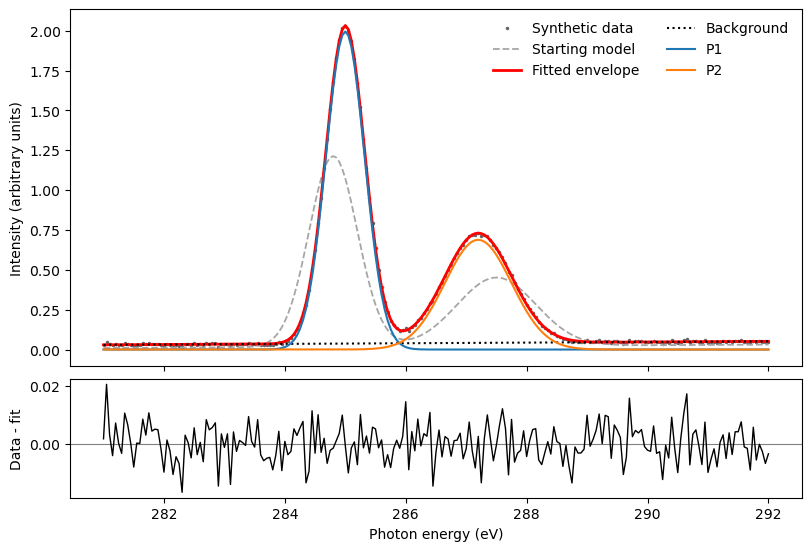

In [4]:
fig, (ax, residual_ax) = plt.subplots(
    2, 1, figsize=(8, 5.4), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}, constrained_layout=True,
)
ax.plot(energy, intensity, ".", color="0.4", ms=3, label="Synthetic data")
ax.plot(energy, initial["total"], "--", color="0.65", lw=1.3, label="Starting model")
ax.plot(energy, components["total"], color="red", lw=2, label="Fitted envelope")
ax.plot(energy, components["baseline"], ":", color="black", label="Background")
for name, curve in components["peaks"].items():
    ax.plot(energy, curve, lw=1.5, label=name)
ax.set_ylabel("Intensity (arbitrary units)")
ax.legend(frameon=False, ncol=2)
residual_ax.axhline(0, color="0.5", lw=0.8)
residual_ax.plot(energy, residual, color="black", lw=1)
residual_ax.set(xlabel="Photon energy (eV)", ylabel="Data - fit")
plt.show()

## Optional: fit a restricted domain without changing the background reference

The background is `b0 + b1 * (E - mean(E))` in this example, because dE is omitted.
The GUI keeps the mean over the full data grid and masks residuals afterwards.
Cropping the input arrays first would instead recenter the background.

The following native residual plus lmfit Minimizer reproduces the full-grid
convention. This is a second, small local fit, not an experimental series fit.

In [5]:
from lmfit import Minimizer

fit_mask = (energy >= 282) & (energy <= 290)
restricted_initial = build_params_from_specs(edge_cfg, peak_specs)

def masked_residual(params):
    full_residual = residual_from_specs(params, energy, intensity, edge_cfg, peak_specs)
    return full_residual[fit_mask]

restricted = Minimizer(masked_residual, restricted_initial).least_squares(
    method="trf", max_nfev=10_000, ftol=1e-8, xtol=1e-8, gtol=1e-8,
)
assert restricted.success, restricted.message
restricted_components = model_components_from_specs(
    restricted.params, energy, edge_cfg=edge_cfg, peak_specs=peak_specs,
)
expected_background = (
    restricted.params["b0"].value
    + restricted.params["b1"].value * (energy - energy.mean())
)
np.testing.assert_allclose(restricted_components["baseline"], expected_background)
assert restricted.ndata == int(fit_mask.sum())
print(f"Restricted fit: {restricted.ndata} of {energy.size} points, using a full-grid background reference.")

# Importing the numerical example must not import a Qt GUI.
assert not any(name.split(".")[0] in {"PySide6", "PyQt6", "PyQt5", "pyqtgraph"}
               for name in sys.modules)

Restricted fit: 161 of 221 points, using a full-grid background reference.


## Save or continue

For a simple local parameter table, `parameter_table.to_csv("parameters.csv")`
writes the table shown above when you choose to run it. No files are written by
this notebook's executable cells.

The GUI exports a fuller retained-fit report through **Export → Fit parameters
CSV…** and **Fitted curves CSV…**. Save session retains the editable GUI workspace.
Opening the starting JSON in this notebook does not reconstruct a complete GUI
session, preparation recipe or a GUI extension that requires generated helper code.

The numerical checks validate this synthetic example, not an uncertainty model
for experimental data. Continue with the book's constraints/statistics reference
before interpreting standard errors, parameter correlations or simultaneous fits.

## Related topics

- [Set up the native environment or inspect the API map](getting-started.md).
- [Perform this same fit through the GUI](../gui/getting-started.md).
- [Extend to a shared fit across three spectra](shared-series-fit.ipynb).
- [Interpret parameter states, bounds and statistics](../reference/constraints.md).
- [Export models that include GUI links or multiple edges](../gui/exporting-fits.md).
